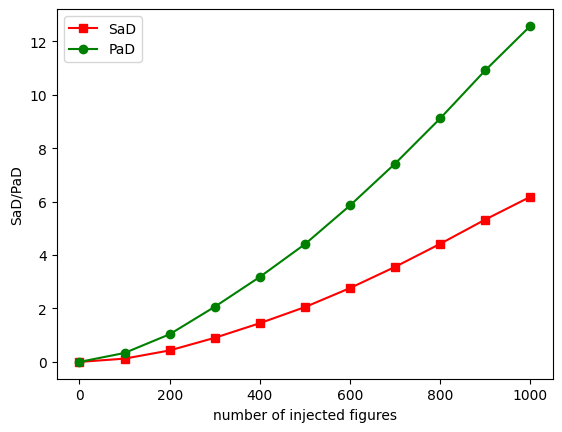

In [1]:
import matplotlib.pyplot as plt                          
                                                         
#折线图                                                     
x = [0,100,200,300,400,500, 600, 700, 800, 900, 1000]#点的横坐标                        
sad = [0, 0.123,0.43,0.902,1.449,2.051, 2.763, 3.557, 4.419, 5.328, 6.18]#线1的纵坐标           
pad = [0, 0.335,1.035,2.0629,3.18,4.406, 5.854, 7.422, 9.112, 10.912, 12.574]#线2的纵坐标           
plt.plot(x,sad,'s-',color = 'r',label="SaD")#s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")#o-:圆形        
plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("SaD/PaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('hcs_KDE_FKL.png', bbox_inches='tight')              
plt.show()                                               

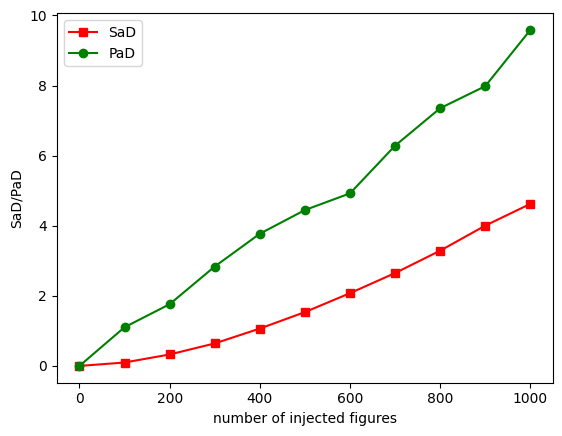

In [2]:
#折线图                                                     
x = [0,100,200,300,400,500, 600, 700, 800, 900, 1000]#点的横坐标                        
sad = [0, 0.0969,0.327,0.642,1.066,1.536, 2.076, 2.65, 3.289, 4.004, 4.624]#线1的纵坐标           
pad = [0, 1.1039,1.761,2.836,3.772,4.448, 4.924, 6.284, 7.354, 7.983, 9.588]#线2的纵坐标           
plt.plot(x,sad,'s-',color = 'r',label="SaD")#s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")#o-:圆形        
plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("SaD/PaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('hcs_KDE_FKL.png', bbox_inches='tight')              
plt.show() 

In [3]:
def my_key(dir_name):
    return int(dir_name.split('_')[-1])

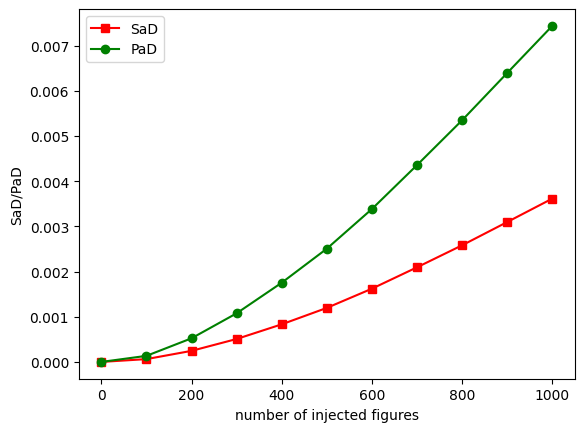

In [6]:
import os
import pickle
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/HCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'].mean())
        pad.append(results['forward_KL_pair'].mean())       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('hcs_GD_FKL.png', bbox_inches='tight')              
plt.show()

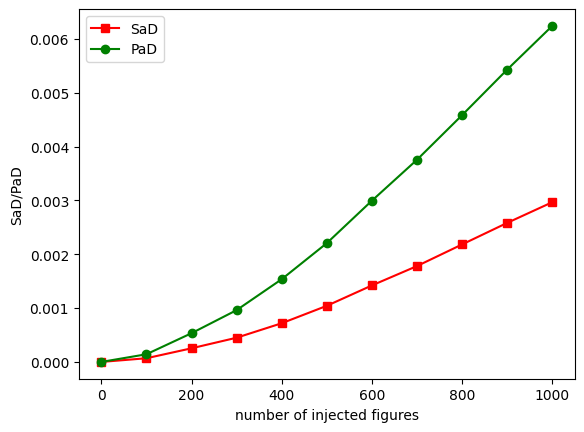

In [7]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/dualCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)
sad = [0]
pad = [0]
for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad.append(results['forward_KL_single'].mean())
        pad.append(results['forward_KL_pair'].mean())       
plt.plot(x,sad,'s-',color = 'r',label="SaD")    #s-:方形        
plt.plot(x,pad,'o-',color = 'g',label="PaD")    #o-:圆形        
plt.xlabel("number of injected figures")    #横坐标名字           
plt.ylabel("SaD/PaD")    #纵坐标名字                              
plt.legend(loc = "best")    #图例                              
plt.savefig('dualcs_GD_FKL.png', bbox_inches='tight')              
plt.show()

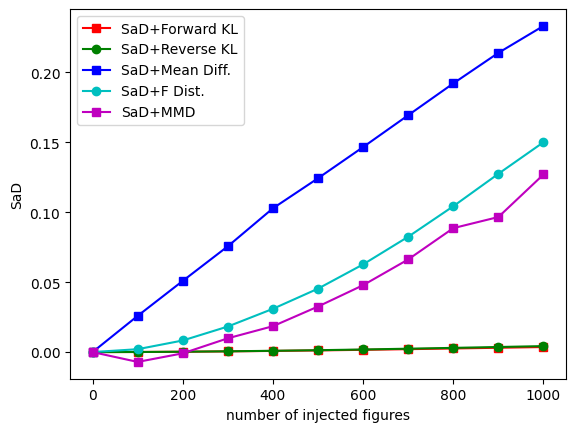

In [10]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/HCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

sad_fkl = [0]
sad_rkl = [0]
sad_md = [0]
sad_fd = [0]
sad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad_fkl.append(results['forward_KL_single'].mean())
        sad_rkl.append(results['reverse_KL_single'].mean())
        sad_md.append(results['mean_difference_single'].mean())
        sad_fd.append(results['f_distance_single'].mean())
        sad_mmd.append(results['kernel_distance_single'].mean()*0.0001)

plt.plot(x,sad_fkl,'s-',color = 'r',label="SaD+Forward KL")#s-:方形        
plt.plot(x,sad_rkl,'o-',color = 'g',label="SaD+Reverse KL")#o-:圆形
plt.plot(x,sad_md,'s-',color = 'b',label="SaD+Mean Diff.")#s-:方形        
plt.plot(x,sad_fd,'o-',color = 'c',label="SaD+F Dist.")#o-:圆形 
plt.plot(x,sad_mmd,'s-',color = 'm',label="SaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("SaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('hcs_sad.png', bbox_inches='tight')              
plt.show()   

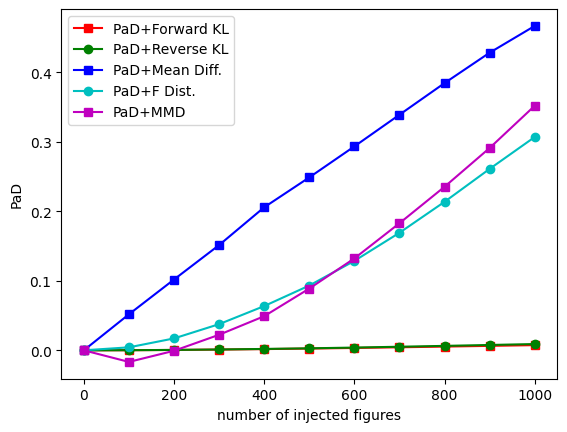

In [13]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/HCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

pad_fkl = [0]
pad_rkl = [0]
pad_md = [0]
pad_fd = [0]
pad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        pad_fkl.append(results['forward_KL_pair'].mean())
        pad_rkl.append(results['reverse_KL_pair'].mean())
        pad_md.append(results['mean_difference_pair'].mean())
        pad_fd.append(results['f_distance_pair'].mean())
        pad_mmd.append(results['kernel_distance_pair'].mean()*0.001)

plt.plot(x,pad_fkl,'s-',color = 'r',label="PaD+Forward KL")#s-:方形        
plt.plot(x,pad_rkl,'o-',color = 'g',label="PaD+Reverse KL")#o-:圆形
plt.plot(x,pad_md,'s-',color = 'b',label="PaD+Mean Diff.")#s-:方形        
plt.plot(x,pad_fd,'o-',color = 'c',label="PaD+F Dist.")#o-:圆形 
plt.plot(x,pad_mmd,'s-',color = 'm',label="PaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("PaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('hcs_pad.png', bbox_inches='tight')              
plt.show() 

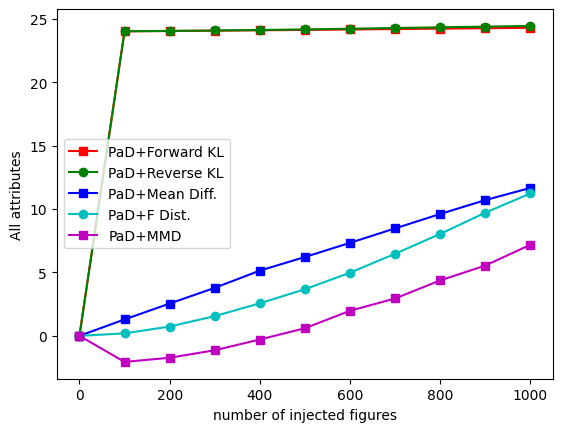

In [25]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/HCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/HCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

pad_fkl = [0]
pad_rkl = [0]
pad_md = [0]
pad_fd = [0]
pad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        pad_fkl.append(results['forward_KL_all'])
        pad_rkl.append(results['reverse_KL_all'])
        pad_md.append(results['mean_difference_all'])
        pad_fd.append(results['f_distance_all'])
        pad_mmd.append(results['kernel_distance_all'])

plt.plot(x,pad_fkl,'s-',color = 'r',label="PaD+Forward KL")#s-:方形        
plt.plot(x,pad_rkl,'o-',color = 'g',label="PaD+Reverse KL")#o-:圆形
plt.plot(x,pad_md,'s-',color = 'b',label="PaD+Mean Diff.")#s-:方形        
plt.plot(x,pad_fd,'o-',color = 'c',label="PaD+F Dist.")#o-:圆形 
plt.plot(x,pad_mmd,'s-',color = 'm',label="PaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("All attributes")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('hcs_all.png', bbox_inches='tight')              
plt.show()

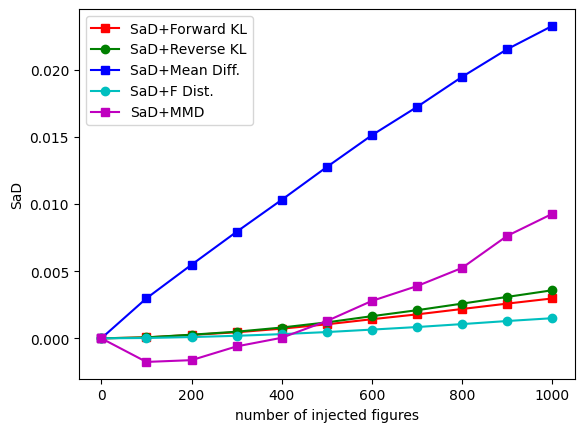

In [26]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/dualCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

sad_fkl = [0]
sad_rkl = [0]
sad_md = [0]
sad_fd = [0]
sad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        sad_fkl.append(results['forward_KL_single'].mean())
        sad_rkl.append(results['reverse_KL_single'].mean())
        sad_md.append(results['mean_difference_single'].mean())
        sad_fd.append(results['f_distance_single'].mean())
        sad_mmd.append(results['kernel_distance_single'].mean())

plt.plot(x,sad_fkl,'s-',color = 'r',label="SaD+Forward KL")#s-:方形        
plt.plot(x,sad_rkl,'o-',color = 'g',label="SaD+Reverse KL")#o-:圆形
plt.plot(x,sad_md,'s-',color = 'b',label="SaD+Mean Diff.")#s-:方形        
plt.plot(x,sad_fd,'o-',color = 'c',label="SaD+F Dist.")#o-:圆形 
plt.plot(x,sad_mmd,'s-',color = 'm',label="SaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("SaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('dualcs_sad.png', bbox_inches='tight')              
plt.show()   

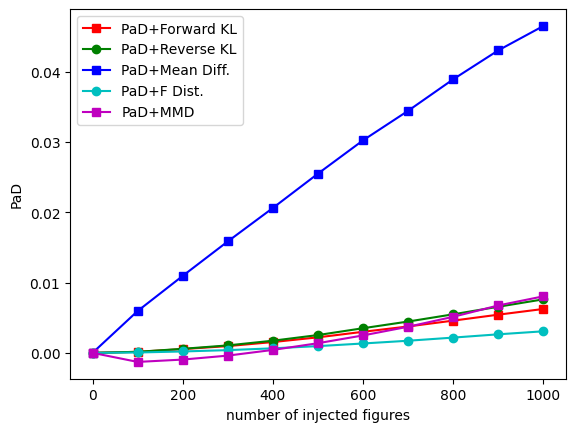

In [27]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/dualCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

pad_fkl = [0]
pad_rkl = [0]
pad_md = [0]
pad_fd = [0]
pad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        pad_fkl.append(results['forward_KL_pair'].mean())
        pad_rkl.append(results['reverse_KL_pair'].mean())
        pad_md.append(results['mean_difference_pair'].mean())
        pad_fd.append(results['f_distance_pair'].mean())
        pad_mmd.append(results['kernel_distance_pair'].mean()*1)

plt.plot(x,pad_fkl,'s-',color = 'r',label="PaD+Forward KL")#s-:方形        
plt.plot(x,pad_rkl,'o-',color = 'g',label="PaD+Reverse KL")#o-:圆形
plt.plot(x,pad_md,'s-',color = 'b',label="PaD+Mean Diff.")#s-:方形        
plt.plot(x,pad_fd,'o-',color = 'c',label="PaD+F Dist.")#o-:圆形 
plt.plot(x,pad_mmd,'s-',color = 'm',label="PaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("PaD")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('dualcs_pad.png', bbox_inches='tight')              
plt.show() 

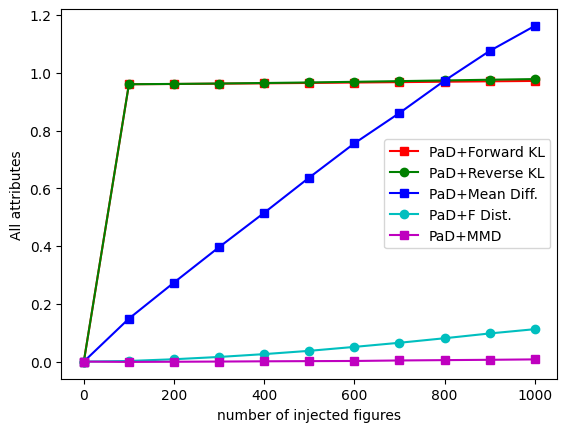

In [31]:
#折线图                                                     
x = list(range(0,1100,100))#点的横坐标
# read experiment results from the path
# base_path = '/Users/yifanlu/Desktop/20250114_fig/dualCS'
base_path = '/Users/yifanlu/Desktop/20250130_figs/results_dir/dualCS'
dirs = sorted((f for f in os.listdir(base_path) if f.startswith("CelebA_5K")), key=my_key)

pad_fkl = [0]
pad_rkl = [0]
pad_md = [0]
pad_fd = [0]
pad_mmd = [0]

for dir in dirs:
    dir_path = os.path.join(base_path, dir)
    with open(f'{dir_path}/experiment_results_dict.pkl', 'rb') as f:
        results = pickle.load(f)
        pad_fkl.append(results['forward_KL_all']/25.)
        pad_rkl.append(results['reverse_KL_all']/25.)
        pad_md.append(results['mean_difference_all'])
        pad_fd.append(results['f_distance_all'])
        pad_mmd.append(results['kernel_distance_all'])

plt.plot(x,pad_fkl,'s-',color = 'r',label="PaD+Forward KL")#s-:方形        
plt.plot(x,pad_rkl,'o-',color = 'g',label="PaD+Reverse KL")#o-:圆形
plt.plot(x,pad_md,'s-',color = 'b',label="PaD+Mean Diff.")#s-:方形        
plt.plot(x,pad_fd,'o-',color = 'c',label="PaD+F Dist.")#o-:圆形 
plt.plot(x,pad_mmd,'s-',color = 'm',label="PaD+MMD")#s-:方形        

plt.xlabel("number of injected figures")#横坐标名字           
plt.ylabel("All attributes")#纵坐标名字                              
plt.legend(loc = "best")#图例                              
plt.savefig('dualcs_all.png', bbox_inches='tight')              
plt.show() 